In [1]:
%pip install wget

from pathlib import Path
import os

os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")

import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=fdbff77cecc5b6e5ba8682178bf02f15cefeda896ade0c71437c405d0de48b13
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")

    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


In [3]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR
            )
        gambar.append(np.asarray(img))
        label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")

del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, \
    "Periksa kelengkapan dataset"

assert np.all(np.bincount(y) == 100), \
    "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


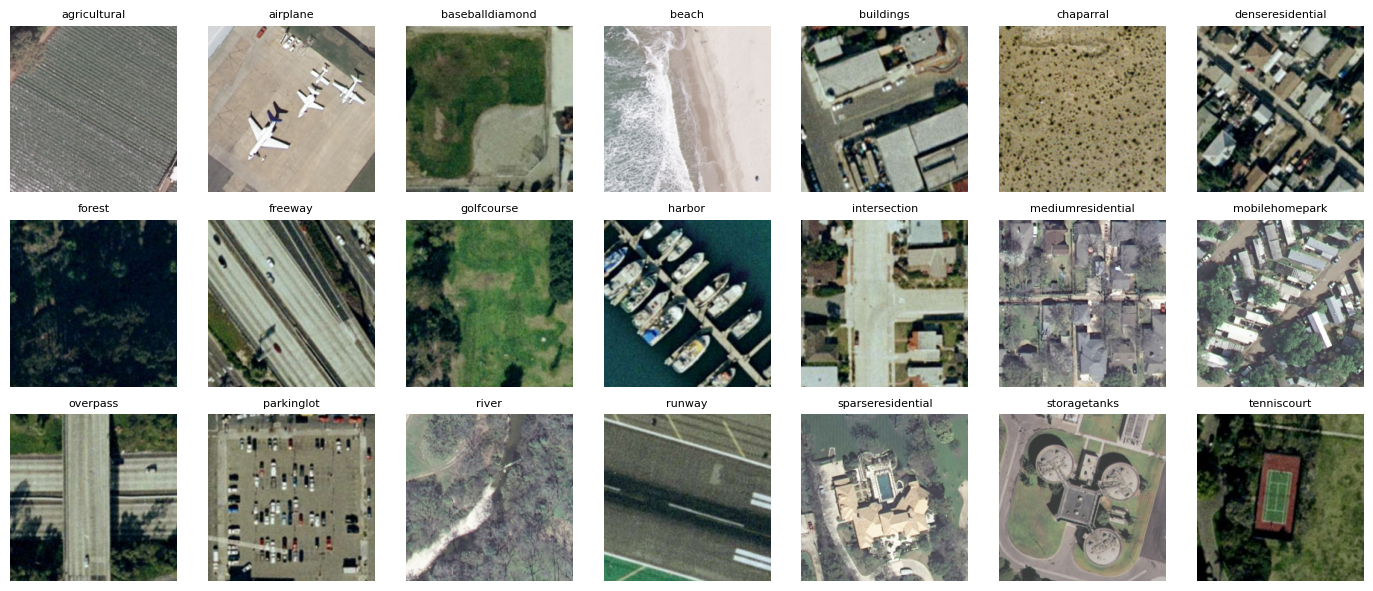

In [4]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_sisa,
    y_sisa,
    test_size=0.50,
    stratify=y_sisa,
    random_state=42
)

print(
    "Train:",
    len(y_train),
    "Validation:",
    len(y_val),
    "Test:",
    len(y_test)
)

Train: 1470 Validation: 315 Test: 315


In [6]:

# MODEL VGG16

base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

# Membekukan backbone VGG16
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# Preprocessing khusus VGG16
x = tf.keras.applications.vgg16.preprocess_input(inputs)

# Ekstraksi fitur
x = base_model(x, training=False)

# Mengubah feature map menjadi vektor
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Mengurangi overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Klasifikasi 21 kelas
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="vgg16_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("Backbone dibekukan:", not base_model.trainable)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 21)        │     10,773 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Backbone dibekukan: True


In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan:", len(history.history["loss"]))

Epoch 1/10
92/92 - 21s - 230ms/step - accuracy: 0.2197 - loss: 5.4677 - val_accuracy: 0.5968 - val_loss: 1.6493
Epoch 2/10
92/92 - 7s - 75ms/step - accuracy: 0.5694 - loss: 1.9561 - val_accuracy: 0.7810 - val_loss: 0.7605
Epoch 3/10
92/92 - 7s - 75ms/step - accuracy: 0.7177 - loss: 1.1429 - val_accuracy: 0.8667 - val_loss: 0.4817
Epoch 4/10
92/92 - 7s - 77ms/step - accuracy: 0.7918 - loss: 0.7067 - val_accuracy: 0.8571 - val_loss: 0.4151
Epoch 5/10
92/92 - 7s - 78ms/step - accuracy: 0.8327 - loss: 0.5810 - val_accuracy: 0.8921 - val_loss: 0.3103
Epoch 6/10
92/92 - 7s - 79ms/step - accuracy: 0.8748 - loss: 0.4343 - val_accuracy: 0.9016 - val_loss: 0.3013
Epoch 7/10
92/92 - 7s - 80ms/step - accuracy: 0.8918 - loss: 0.3687 - val_accuracy: 0.9175 - val_loss: 0.2471
Epoch 8/10
92/92 - 8s - 82ms/step - accuracy: 0.9075 - loss: 0.3024 - val_accuracy: 0.9270 - val_loss: 0.2289
Epoch 9/10
92/92 - 8s - 84ms/step - accuracy: 0.9211 - loss: 0.2144 - val_accuracy: 0.9302 - val_loss: 0.2261
Epoch 10

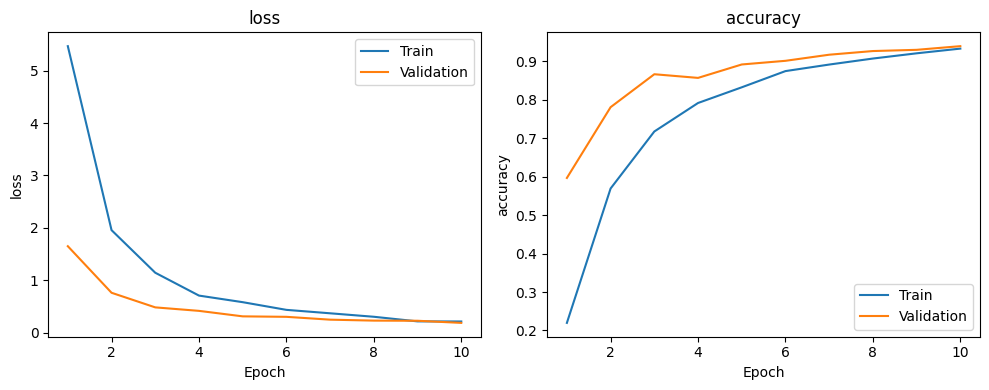

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss: 0.2523 | Test accuracy: 91.43%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       0.94      1.00      0.97        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.69      0.73      0.71        15
        chaparral       1.00      0.93      0.97        15
 denseresidential       0.75      0.80      0.77        15
           forest       0.88      1.00      0.94        15
          freeway       1.00      0.93      0.97        15
       golfcourse       0.93      0.87      0.90        15
           harbor       1.00      1.00      1.00        15
     intersection       0.63      0.80      0.71        15
mediumresidential       0.82      0.93      0.88        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       1.00      0.87      0.93        15
       parkin

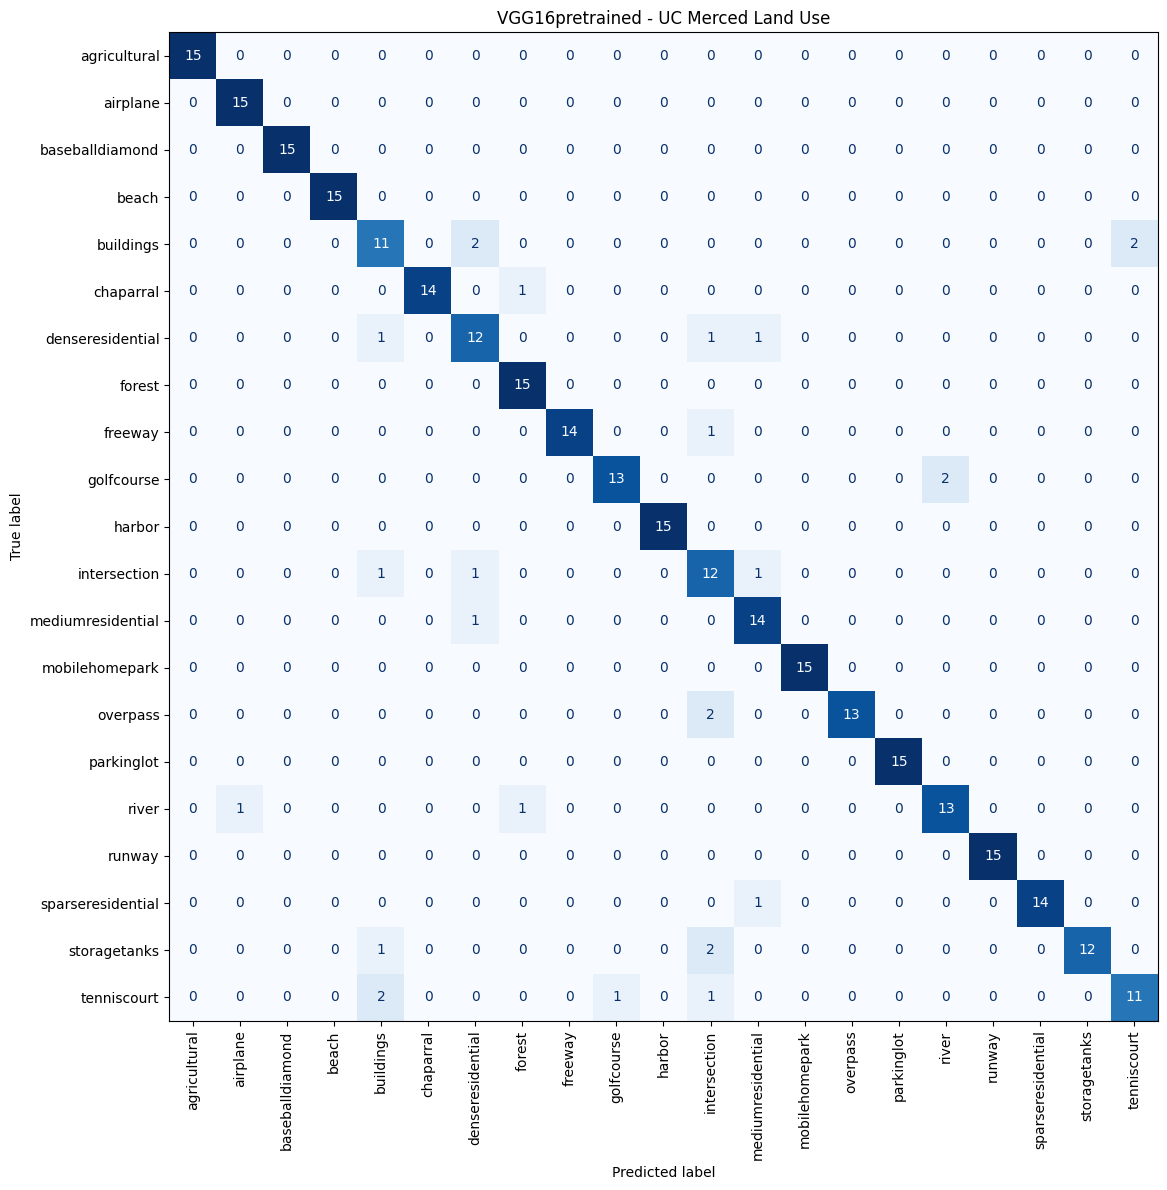

In [9]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss: {test_loss:.4f} | "
    f"Test accuracy: {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("VGG16pretrained - UC Merced Land Use")

plt.tight_layout()
plt.show()

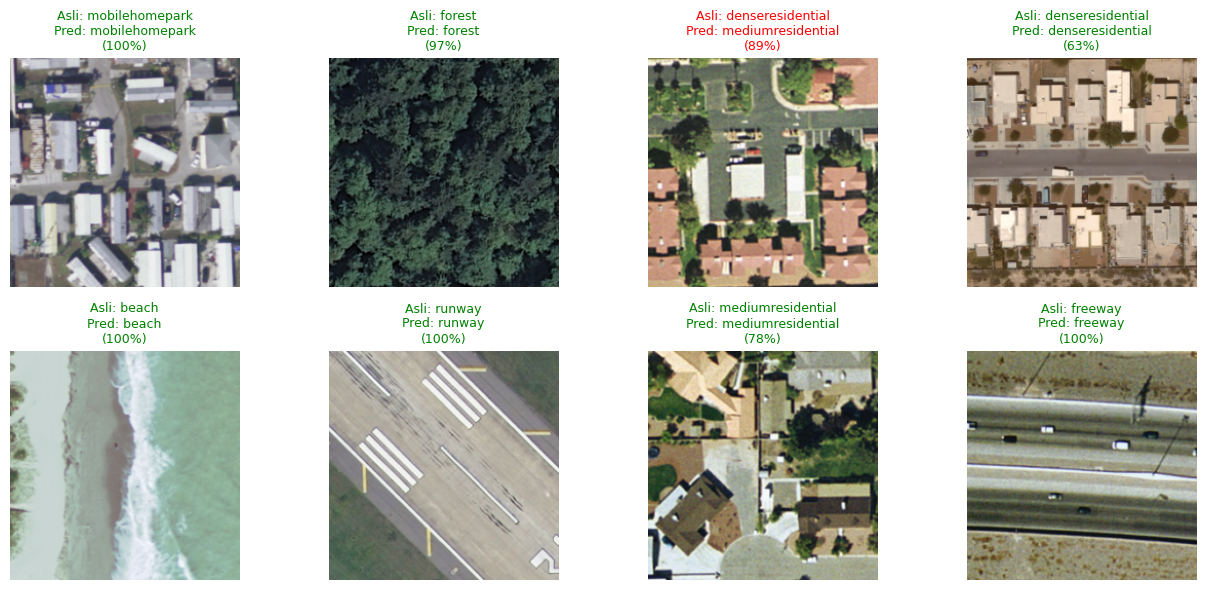

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]}\n"
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()